In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
data={
    'student':['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P','Q','R','S','T'],
    'Marks':[45,50,52,48,55,60,58,62,65,59,61,57,63,56,54,51,49,95,100,5]

}

df=pd.DataFrame(data)
print(df)

   student  Marks
0        A     45
1        B     50
2        C     52
3        D     48
4        E     55
5        F     60
6        G     58
7        H     62
8        I     65
9        J     59
10       K     61
11       L     57
12       M     63
13       N     56
14       O     54
15       P     51
16       Q     49
17       R     95
18       S    100
19       T      5


In [3]:
plt.figure(figsize=(8,5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Axes: ylabel='Marks'>

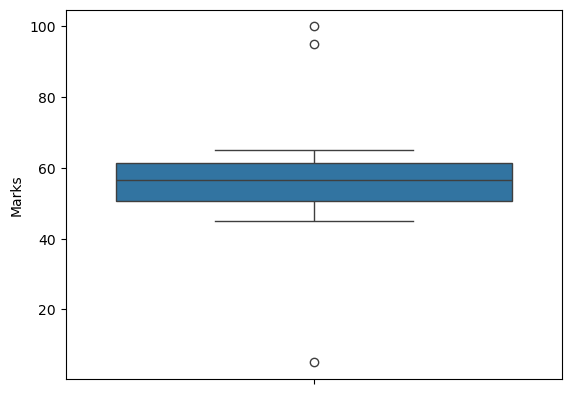

In [4]:
sns.boxplot(y=df['Marks'])

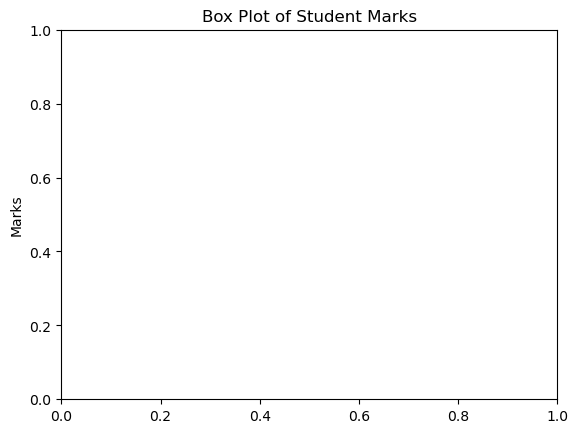

In [5]:
plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")
plt.show()

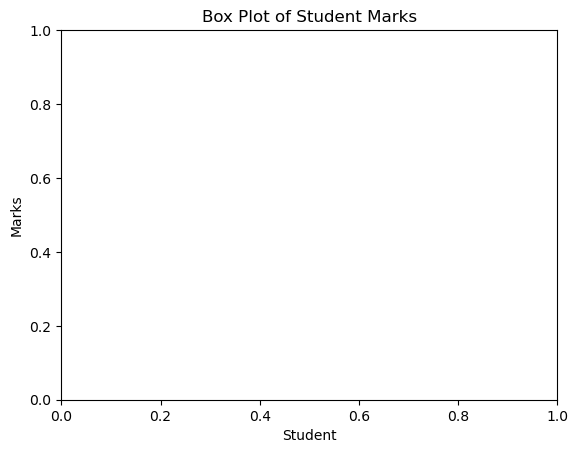

In [6]:
plt.title("Box Plot of Student Marks")
plt.xlabel("Student")
plt.ylabel("Marks")
plt.show()

In [7]:
q1=df['Marks'].quantile(0.25)
q3=df['Marks'].quantile(0.75)
print("q1=",q1)
print("q3=",q3)

q1= 50.75
q3= 61.25


In [8]:
iqr=q3-q1
print("iqr=",iqr)

iqr= 10.5


In [9]:
lower_limit=q1-1.5*iqr
upper_limit=q3+1.5*iqr
print("lower_limit=",lower_limit)
print("upper_limit=",upper_limit)

lower_limit= 35.0
upper_limit= 77.0


In [10]:
outliers_iqr=df[
    (df['Marks']<lower_limit) |
    (df['Marks']>upper_limit)
    ]
print("outliers detected using iqr:")
print(outliers_iqr)

outliers detected using iqr:
   student  Marks
17       R     95
18       S    100
19       T      5


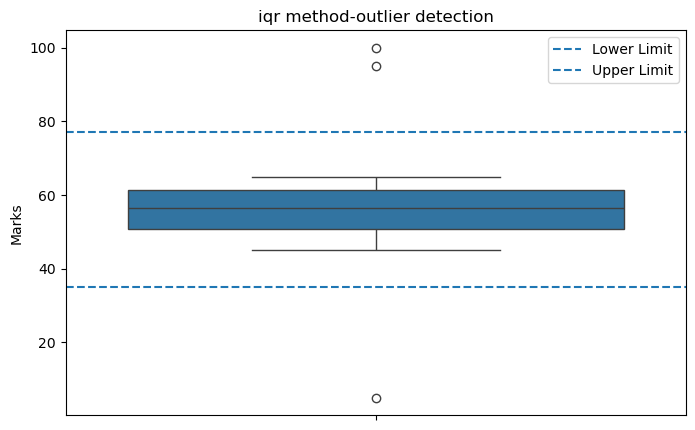

In [11]:
plt.figure(figsize=(8,5))
sns.boxplot(y=df['Marks'])
plt.axhline(lower_limit,linestyle='--',label='Lower Limit')
plt.axhline(upper_limit,linestyle='--',label='Upper Limit')
plt.title("iqr method-outlier detection")
plt.legend()
plt.show()

In [12]:
df['Marks_iqr_capped']=df['Marks'].clip(lower=lower_limit,upper=upper_limit)
print(df[['Marks','Marks_iqr_capped']])

    Marks  Marks_iqr_capped
0      45                45
1      50                50
2      52                52
3      48                48
4      55                55
5      60                60
6      58                58
7      62                62
8      65                65
9      59                59
10     61                61
11     57                57
12     63                63
13     56                56
14     54                54
15     51                51
16     49                49
17     95                77
18    100                77
19      5                35


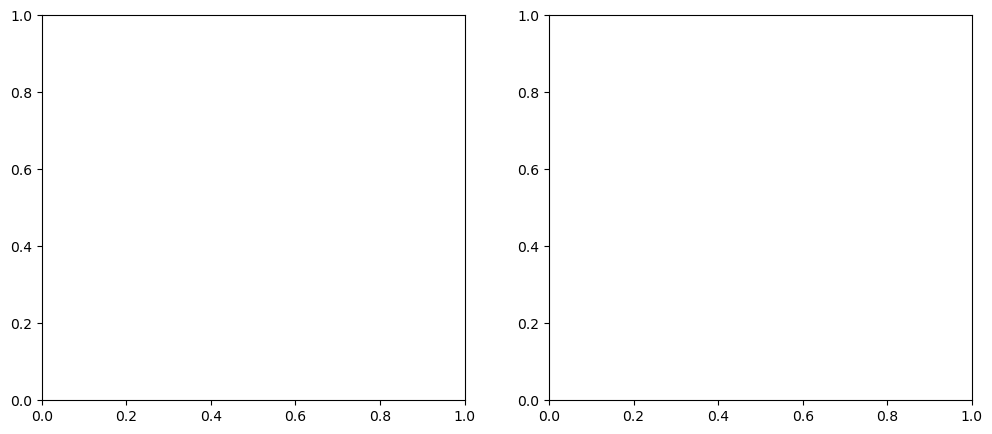

In [13]:
fig,axes=plt.subplots(1,2,figsize=(12,5))

In [15]:
df['Z_score']=(df['Marks']-df['Marks'].mean())/df['Marks'].std()
print(df[['Marks','Z_score']])

    Marks   Z_score
0      45 -0.659078
1      50 -0.390067
2      52 -0.282462
3      48 -0.497671
4      55 -0.121055
5      60  0.147956
6      58  0.040352
7      62  0.255561
8      65  0.416968
9      59  0.094154
10     61  0.201759
11     57 -0.013451
12     63  0.309363
13     56 -0.067253
14     54 -0.174857
15     51 -0.336264
16     49 -0.443869
17     95  2.031037
18    100  2.300048
19      5 -2.811170


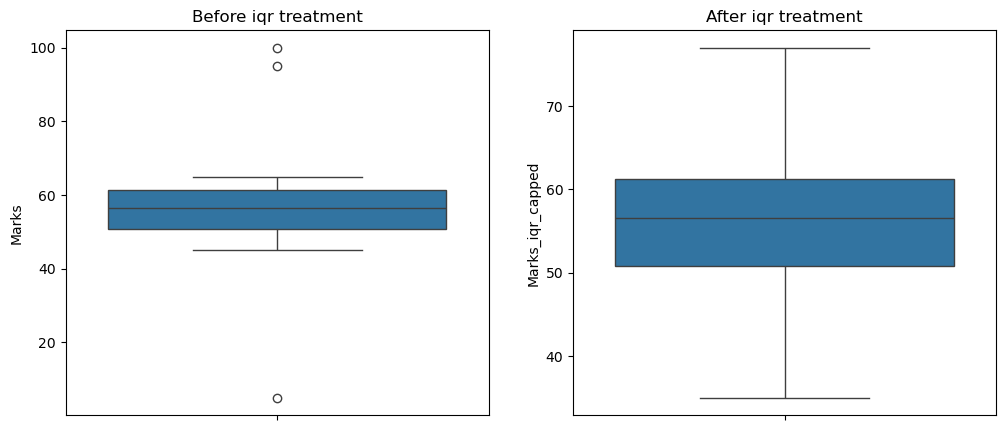

In [16]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
sns.boxplot(y=df['Marks'],ax=axes[0])
axes[0].set_title("Before iqr treatment")
sns.boxplot(y=df['Marks_iqr_capped'],ax=axes[1])
axes[1].set_title("After iqr treatment")
plt.show()

In [17]:
df['Z_score']=stats.zscore(df['Marks'])
print(df[['Marks','Z_score']])

    Marks   Z_score
0      45 -0.676200
1      50 -0.400200
2      52 -0.289800
3      48 -0.510600
4      55 -0.124200
5      60  0.151800
6      58  0.041400
7      62  0.262200
8      65  0.427800
9      59  0.096600
10     61  0.207000
11     57 -0.013800
12     63  0.317400
13     56 -0.069000
14     54 -0.179400
15     51 -0.345000
16     49 -0.455400
17     95  2.083800
18    100  2.359799
19      5 -2.884199


In [18]:
z_outliers=df[df['Z_score'].abs()>3]
print("outliers detected using z-score:")
print(z_outliers)

outliers detected using z-score:
Empty DataFrame
Columns: [student, Marks, Marks_iqr_capped, Z_score]
Index: []


In [19]:
df['z_outlier']=abs(df['Z_score'])>3
print(df[['Marks','Z_score','z_outlier']])

    Marks   Z_score  z_outlier
0      45 -0.676200      False
1      50 -0.400200      False
2      52 -0.289800      False
3      48 -0.510600      False
4      55 -0.124200      False
5      60  0.151800      False
6      58  0.041400      False
7      62  0.262200      False
8      65  0.427800      False
9      59  0.096600      False
10     61  0.207000      False
11     57 -0.013800      False
12     63  0.317400      False
13     56 -0.069000      False
14     54 -0.179400      False
15     51 -0.345000      False
16     49 -0.455400      False
17     95  2.083800      False
18    100  2.359799      False
19      5 -2.884199      False


In [20]:
mean=df['Marks'].mean()
std=df['Marks'].std()
print("mean=",mean)
print("std=",std)

mean= 57.25
std= 18.586568438412442


In [21]:
mean=df['Marks'].mean()
std=df['Marks'].std()
lower_z_limit=mean-(3*std)
upper_z_limit=mean+(3*std)
print("lower_z_limit=",lower_z_limit)
print("upper_z_limit=",upper_z_limit)

lower_z_limit= 1.4902946847626737
upper_z_limit= 113.00970531523733


In [22]:
df['Marks_z_capped']=df['Marks'].clip(lower=lower_z_limit,upper=upper_z_limit)
print(df[['Marks','Marks_z_capped']])

    Marks  Marks_z_capped
0      45              45
1      50              50
2      52              52
3      48              48
4      55              55
5      60              60
6      58              58
7      62              62
8      65              65
9      59              59
10     61              61
11     57              57
12     63              63
13     56              56
14     54              54
15     51              51
16     49              49
17     95              95
18    100             100
19      5               5


In [23]:
print(df[['Marks','Marks_iqr_capped','Marks_z_capped']])

    Marks  Marks_iqr_capped  Marks_z_capped
0      45                45              45
1      50                50              50
2      52                52              52
3      48                48              48
4      55                55              55
5      60                60              60
6      58                58              58
7      62                62              62
8      65                65              65
9      59                59              59
10     61                61              61
11     57                57              57
12     63                63              63
13     56                56              56
14     54                54              54
15     51                51              51
16     49                49              49
17     95                77              95
18    100                77             100
19      5                35               5


    Marks  Marks_iqr_capped  Marks_z_capped
0      45                45              45
1      50                50              50
2      52                52              52
3      48                48              48
4      55                55              55
5      60                60              60
6      58                58              58
7      62                62              62
8      65                65              65
9      59                59              59
10     61                61              61
11     57                57              57
12     63                63              63
13     56                56              56
14     54                54              54
15     51                51              51
16     49                49              49
17     95                77              95
18    100                77             100
19      5                35               5


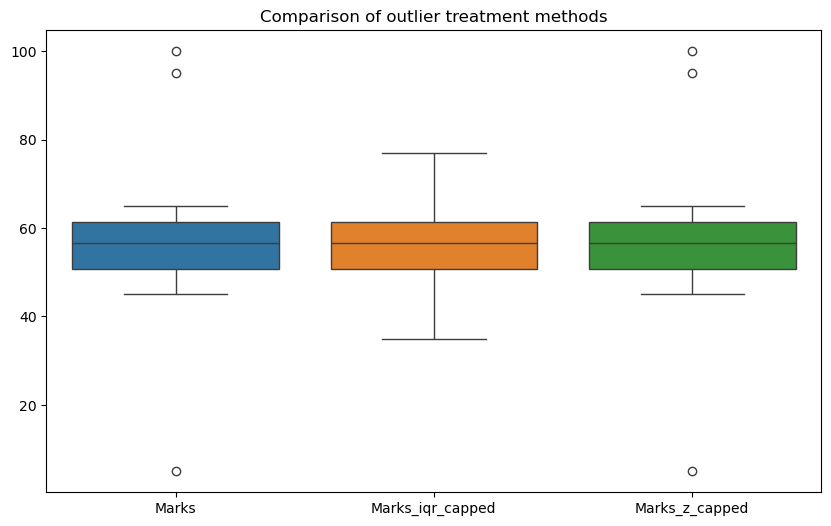

In [24]:
print(df[['Marks','Marks_iqr_capped','Marks_z_capped']])
plt.figure(figsize=(10,6))
sns.boxplot(data=df[['Marks','Marks_iqr_capped','Marks_z_capped']])
plt.title("Comparison of outlier treatment methods")
plt.show()
